In [1]:
from pathlib import Path
import json, os, platform, shutil, subprocess, sys, tempfile, time, zipfile, warnings
from concurrent.futures import ThreadPoolExecutor, as_completed

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 180)
pd.set_option("display.width", 240)

ROOT = Path.cwd()
TRACE_ORIGIN = pd.Timestamp("2024-03-01 00:00:00")
PRIMARY_GPU = "A100-SXM4-80GB"
CAPACITY = 3456
HOURS_PER_EVAL = 168

PRINCIPAL_REPS = ["R05","R06","R07","R08","R09"]
NATIVE_GFS_SEEDS = [2026,2027,2028]

RESUME = True
RUN_MATCHED_GFS = True
RUN_PREFLIGHT = True

MAX_WORKERS = 2
TRAIN_EPOCHS = 10
PATIENCE = 3
BATCH_SIZE = 32
DATALOADER_WORKERS = 0

OUT = ROOT/"outputs_fame_gpu_05_v7"
RUNS = ROOT/"fame_gpu_05_v7_runs"
BRANCH_DIR = RUNS/"branches"
MODEL_DIR = RUNS/"model_checkpoints"
A100_DATA_DIR = RUNS/"a100_only_data"

for p in [OUT,RUNS,BRANCH_DIR,MODEL_DIR,A100_DATA_DIR]:
    p.mkdir(parents=True,exist_ok=True)

print("Host Python:",sys.version.split()[0])
print("OS:",platform.platform())
print("Seeds:",NATIVE_GFS_SEEDS)

Host Python: 3.13.14
OS: Windows-11-10.0.26200-SP0
Seeds: [2026, 2027, 2028]


In [2]:
def locate(name):
    for p in [ROOT/name, Path("/mnt/data")/name]:
        if p.exists() and p.is_dir():
            return p
    for z in [ROOT/f"{name}.zip", Path("/mnt/data")/f"{name}.zip"]:
        if z.exists():
            target=ROOT/f"{name}_05v6_extract"
            target.mkdir(exist_ok=True)
            with zipfile.ZipFile(z) as zz:
                zz.extractall(target)
            p=target/name
            if p.exists():
                return p
    raise FileNotFoundError(name)

OUT1 = locate("outputs_fame_gpu")
OUT4C = locate("outputs_fame_gpu_04c")
OUT5V5 = locate("outputs_fame_gpu_05_v5")

windows = pd.read_csv(
    OUT1/"fame_windows_7d.csv",
    parse_dates=["D_start","D_end_exclusive","C_start","C_end_exclusive","E_start","E_end_exclusive"]
)
windows = windows[windows["replication"].isin(PRINCIPAL_REPS)].copy()

fame = pd.read_csv(OUT4C/"consistent_frozen_transfer_summary.csv")
fame = fame[fame["replication"].isin(PRINCIPAL_REPS)].copy()

continuous = pd.read_csv(OUT5V5/"external_continuous_GFS_comparison.csv")
continuous = continuous[continuous["replication"].isin(PRINCIPAL_REPS)].copy()

display(
    fame[
        ["replication","phi_C_q","phi_C_H",
         "frozen_E_allocation","frozen_E_eviction",
         "reference_E_allocation","reference_E_eviction"]
    ]
)

,replication,phi_C_q,phi_C_H,frozen_E_allocation,frozen_E_eviction,reference_E_allocation,reference_E_eviction
1,R05,0.90,4,0.891234,0.002902,0.892441,0.001140
2,R06,0.80,4,0.836255,0.010957,0.835578,0.006708
3,R07,0.90,4,0.819209,0.015832,0.819371,0.014180
4,R08,0.95,2,0.894328,0.003604,0.891467,0.003223
5,R09,0.99,4,0.885656,0.013135,0.882135,0.017640


In [3]:
DATA_DIR=None
for p in [ROOT/"data_fame_gpu", Path("/mnt/data")/"data_fame_gpu"]:
    if (p/"job_info_df.csv").exists() and (p/"node_info_df.csv").exists():
        DATA_DIR=p
        break

if DATA_DIR is None:
    raise FileNotFoundError("data_fame_gpu não encontrada.")

jobs_all=pd.read_csv(DATA_DIR/"job_info_df.csv")
nodes_all=pd.read_csv(DATA_DIR/"node_info_df.csv")

jobs_a100=jobs_all[jobs_all["gpu_model"]==PRIMARY_GPU].copy()
nodes_a100=nodes_all[nodes_all["gpu_model"]==PRIMARY_GPU].copy()

jobs_a100.to_csv(A100_DATA_DIR/"job_info_df.csv",index=False)
nodes_a100.to_csv(A100_DATA_DIR/"node_info_df.csv",index=False)

assert (jobs_a100["gpu_model"]==PRIMARY_GPU).all()
assert (nodes_a100["gpu_model"]==PRIMARY_GPU).all()

print("A100 jobs:",len(jobs_a100))
print("A100 nodes:",len(nodes_a100))

A100 jobs: 169020
A100 nodes: 432


In [4]:
ENV_DIR=ROOT/".venv_gfs_native"

NATIVE_PYTHON = (
    ENV_DIR/"Scripts"/"python.exe"
    if os.name=="nt"
    else ENV_DIR/"bin"/"python"
)

if not NATIVE_PYTHON.exists():
    raise FileNotFoundError(".venv_gfs_native não encontrado.")

def nr(args,**kwargs):
    return subprocess.run(
        [str(NATIVE_PYTHON)]+args,
        text=True,stdout=subprocess.PIPE,stderr=subprocess.STDOUT,
        **kwargs
    )

p=nr([
    "-c",
    "import json,sys,torch; print(json.dumps({'python':sys.version,'torch':torch.__version__,'cuda':torch.cuda.is_available(),'gpu':torch.cuda.get_device_name(0) if torch.cuda.is_available() else None}))"
])

if p.returncode!=0:
    print(p.stdout)
    raise RuntimeError("Ambiente Native GFS inválido.")

native_env=json.loads(p.stdout.strip().splitlines()[-1])
display(pd.Series(native_env).to_frame("value"))

try:
    import psutil
    PHYSICAL_CPUS=psutil.cpu_count(logical=False) or max(1,(os.cpu_count() or 2)//2)
except Exception:
    PHYSICAL_CPUS=max(1,(os.cpu_count() or 2)//2)

USE_GPU=bool(native_env.get("cuda",False))

if USE_GPU:
    MAX_WORKERS=1

TORCH_THREADS_PER_BRANCH=max(
    1,
    min(6,(PHYSICAL_CPUS-1)//max(1,MAX_WORKERS))
)

print("Physical CPUs:",PHYSICAL_CPUS)
print("Use GPU:",USE_GPU)
print("Workers:",MAX_WORKERS)
print("Torch threads/branch:",TORCH_THREADS_PER_BRANCH)

,value
python,"3.12.6 (tags/v3.12.6:a4a2d2b, Sep 6 2024, 20:..."
torch,2.4.1+cpu
cuda,False
gpu,None


Physical CPUs: 12
Use GPU: False
Workers: 2
Torch threads/branch: 5


In [5]:
GFS_ORIGINAL=ROOT/"26ASPLOS-Spot"

if not GFS_ORIGINAL.exists():
    p=subprocess.run(
        ["git","clone","--depth","1",
         "https://github.com/MachineLearningSystem/26ASPLOS-Spot.git",
         str(GFS_ORIGINAL)],
        text=True,stdout=subprocess.PIPE,stderr=subprocess.STDOUT
    )
    if p.returncode!=0:
        raise RuntimeError(p.stdout)

git_head=subprocess.run(
    ["git","-C",str(GFS_ORIGINAL),"rev-parse","HEAD"],
    text=True,stdout=subprocess.PIPE,stderr=subprocess.STDOUT
).stdout.strip()

WORK=Path(tempfile.mkdtemp(prefix="fame_gpu_05v6_"))
GFS=WORK/"26ASPLOS-Spot-Native"

shutil.copytree(
    GFS_ORIGINAL,GFS,
    ignore=shutil.ignore_patterns(".git","__pycache__","*.pyc",".pytest_cache")
)

(GFS/"policy"/"__init__.py").write_text(
    "from .spot import SpotScheduler\n",
    encoding="utf-8"
)

u=GFS/"utils.py"
txt=u.read_text(encoding="utf-8")
i0=txt.find("from policy import (")
if i0!=-1:
    i1=txt.find(")\n",i0)
    txt=txt[:i0]+"from policy import SpotScheduler\n"+txt[i1+2:]
u.write_text(txt,encoding="utf-8")

print("GFS commit:",git_head)

GFS commit: e998d5453e626a0b743b3fd5137c54c987db780b


In [6]:
fast_src = r"""
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
from torch.utils.data import Dataset
from chinese_calendar import is_workday

class Dataset_GPU_Org_FastExact(Dataset):
    def __init__(self,args,data=None,timestamp=None,flag='train',size=None,scale=False,timeenc=0,freq='h'):
        self.args=args
        self.val_days=7
        self.stride_size=5
        if size is None:
            self.seq_len=384; self.label_len=96; self.pred_len=96
        else:
            self.seq_len,self.label_len,self.pred_len=size
        self.set_type={'train':0,'val':1,'test':2}[flag]
        self.scale=scale
        self.timeenc=timeenc
        self.freq=freq

        # Interface compatibility with the public Dataset_GPU_Org.
        # The native estimator accesses data_set.cov_dicts during training.
        self.cov_dicts=[]

        self.vc_key_dicts={}
        self.inverse_vc_key_dicts={}
        self.scaler=StandardScaler()
        self.timestamp=timestamp
        self.__read_data__(data)

    def __read_data__(self,df_raw):
        df_raw.index=pd.DatetimeIndex(df_raw.index)
        train0=pd.Timestamp("2024-03-01 20:00:00")
        val0=self.timestamp-pd.Timedelta(days=self.val_days,hours=self.seq_len)
        val1=self.timestamp-pd.Timedelta(minutes=1)
        train1=val1-pd.Timedelta(days=self.val_days)
        b1=[train0,val0][self.set_type]
        b2=[train1,val1][self.set_type]
        self.data_stamp=df_raw[b1:b2].index
        self.class_data=self.fit_class(df_raw.columns)
        if self.scale:
            tr=df_raw[train0:train1]
            self.scaler.fit(tr.values)
            data=self.scaler.transform(df_raw[b1:b2].values)
        else:
            data=df_raw[b1:b2].values
        self.data_x=data
        self.data_y=data
        self.phase_hourly=[]
        for phase in range(12):
            arr=data[phase*5:]
            nh=arr.shape[0]//60
            arr=arr[:nh*60]
            hourly=(arr.reshape(nh,60,arr.shape[1]).max(axis=1)
                    if nh else np.empty((0,data.shape[1]),dtype=data.dtype))
            self.phase_hourly.append(hourly)

    def __getitem__(self,index):
        sb=index*5
        se=sb+self.seq_len*60
        phase=index%12
        h0=index//12
        hourly=self.phase_hourly[phase]
        sx=hourly[h0:h0+self.seq_len]
        mark=self.get_covariates(self.data_stamp[se])
        mark=np.expand_dims(mark,1).repeat(sx.shape[1],axis=1).T
        y0=h0+self.seq_len-self.label_len
        sy=hourly[y0:y0+self.label_len+self.pred_len]
        return sx,mark,self.class_data.T,sy

    def __len__(self):
        return (len(self.data_x)-self.seq_len*60-self.pred_len*60)//5+1

    def inverse_transform(self,data):
        return self.scaler.inverse_transform(data)

    def get_covariates(self,time):
        c=np.zeros(self.args.num_covariates)
        c[0]=is_workday(time)
        c[1]=time.weekday()
        c[2]=time.hour
        return c

    def fit_class(self,columns):
        for i in range(self.args.num_class):
            keys=pd.Series([x[i] for x in columns.str.split('&&',expand=True)])
            self.vc_key_dicts[i]=dict(zip(keys.unique(),range(keys.nunique())))
            self.inverse_vc_key_dicts[i]=dict(zip(range(keys.nunique()),keys.unique()))
        vals=[]
        for col in columns:
            k=col.split('&&')
            vals.append([self.vc_key_dicts[i][k[i]] for i in range(self.args.num_class)])
        return np.array(vals)
"""

(GFS/"estimator"/"data_loader_fast_exact.py").write_text(fast_src,encoding="utf-8")

ep=GFS/"estimator"/"gpu_request_estimator.py"
t=ep.read_text(encoding="utf-8")
t=t.replace(
    "from estimator.data_loader import Dataset_GPU_Org",
    "from estimator.data_loader_fast_exact import Dataset_GPU_Org_FastExact as Dataset_GPU_Org",
    1
)
t=t.replace(
    "path = os.path.join(self.args.checkpoints, str(now_timestamp))",
    "safe_timestamp = str(now_timestamp).replace(':', '-')\n        path = os.path.join(self.args.checkpoints, safe_timestamp)",
    1
)
ep.write_text(t,encoding="utf-8")

p=nr(["-m","py_compile",str(ep),str(GFS/"estimator"/"data_loader_fast_exact.py")],cwd=GFS)
if p.returncode!=0:
    print(p.stdout)
    raise RuntimeError("Estimator patch inválido.")
print("[PATCH COMPILE OK]")

[PATCH COMPILE OK]


In [7]:
test_src = r"""
from argparse import Namespace
import numpy as np, pandas as pd
from estimator.data_loader import Dataset_GPU_Org
from estimator.data_loader_fast_exact import Dataset_GPU_Org_FastExact

rng=np.random.default_rng(2026)
n=50*24*60
idx=pd.date_range("2024-03-01 20:00:00",periods=n,freq="min")
cols=pd.Index([f"A100-SXM4-80GB&&cluster&&org{i}" for i in range(6)])
df=pd.DataFrame(rng.integers(0,20,size=(n,len(cols))).astype(float),index=idx,columns=cols)
args=Namespace(num_covariates=3,num_class=3)
ts=pd.Timestamp("2024-04-19 20:00:00")

for flag in ["train","val"]:
    a=Dataset_GPU_Org(args=args,flag=flag,data=df.copy(),timestamp=ts,size=[672,24,4],timeenc=1,freq="h",scale=False)
    b=Dataset_GPU_Org_FastExact(args=args,flag=flag,data=df.copy(),timestamp=ts,size=[672,24,4],timeenc=1,freq="h",scale=False)
    assert len(a)==len(b)

    # Public-interface compatibility required by GPURequestEstimator.
    assert hasattr(b,"cov_dicts")
    assert b.cov_dicts == a.cov_dicts
    assert np.array_equal(b.class_data,a.class_data)
    assert b.vc_key_dicts == a.vc_key_dicts
    assert b.inverse_vc_key_dicts == a.inverse_vc_key_dicts
    assert b.scale == a.scale

    for i in sorted(set([0,1,11,12,13,len(a)//2,len(a)-2,len(a)-1])):
        aa=a[i]; bb=b[i]
        for j in range(4):
            assert np.array_equal(np.asarray(aa[j]),np.asarray(bb[j])),(flag,i,j)

print("FAST_EXACT_EQUIVALENCE_OK")
print("FAST_EXACT_INTERFACE_OK")
"""

tp=GFS/"validate_fast_exact.py"
tp.write_text(test_src,encoding="utf-8")
p=nr([str(tp)],cwd=GFS,timeout=900)
print(p.stdout)
if (p.returncode!=0 or "FAST_EXACT_EQUIVALENCE_OK" not in p.stdout or "FAST_EXACT_INTERFACE_OK" not in p.stdout):
    raise RuntimeError("FastExact não reproduziu exatamente o dataset original.")

FAST_EXACT_EQUIVALENCE_OK
FAST_EXACT_INTERFACE_OK



In [8]:
sched_src = r"""
import os, shutil, time
import numpy as np
import pandas as pd
from .spot import SpotScheduler

class SilentLogger:
    def info(self,*a,**k): pass
    def warning(self,*a,**k): pass
    def error(self,*a,**k): pass

class NativeBenchmarkScheduler(SpotScheduler):
    def __init__(self,trace,cluster,args,log_dir,logger=None):
        if logger is None: logger=SilentLogger()
        super().__init__(trace,cluster,args,log_dir,logger)
        self.prev_index=0
        self.fast_history_initialized=False
        self.org_history=None
        self.org_buffer=[]
        self.metric_rows=[]
        self.training_runtime=[]

    def _upgrade_legacy_state(self):
        defaults={
            "prev_index":0,
            "fast_history_initialized":False,
            "org_history":None,
            "org_buffer":[],
            "metric_rows":[],
            "training_runtime":[],
            "org_keys":None,
            "train_timestamp_base":None,
        }
        for k,v in defaults.items():
            if not hasattr(self,k):
                setattr(self,k,v)
        return self

    def initialize_fast_history(self):
        self._upgrade_legacy_state()
        if self.fast_history_initialized:
            return
        self.org_history=self.recorder.agg_seq_recorder().copy()
        self.org_keys=list(self.guar_request_dict.keys())
        self.train_timestamp_base=self.recorder.train_start_timestamp
        self.org_buffer=[]
        self.metric_rows=[]
        self.training_runtime=[]
        self.recorder.org_request_df_list=[]
        self.recorder.record_df_list=[]
        self.recorder.vc_record_df_list=[]
        self.fast_history_initialized=True

    def flush_org_buffer(self):
        if not self.org_buffer:
            return self.org_history
        idx=pd.DatetimeIndex([r[0] for r in self.org_buffer])
        vals=np.asarray([r[1] for r in self.org_buffer],dtype=float)
        new=pd.DataFrame(vals,index=idx,columns=self.org_keys)
        self.org_history=pd.concat([self.org_history,new],axis=0)
        self.org_buffer=[]
        return self.org_history

    def record_minute_fast(self):
        vc_name=next(iter(self.cluster.vc_dict.keys()))
        vc=self.cluster.vc_dict[vc_name]
        self.metric_rows.append({
            "time":self.time,
            "total_gpu_num":vc.total_gpus,
            "idle_gpu_num":vc.vc_free_gpus(),
            "guar_que_job_num":len(self.guar_que_list[vc_name]),
            "spot_que_job_num":len(self.spot_que_list[vc_name]),
        })
        ts=self.train_timestamp_base+pd.Timedelta(seconds=self.time)
        vals=[self.guar_request_dict[k] for k in self.org_keys]
        self.org_buffer.append((ts,vals))

    def current_org_data(self):
        return self.flush_org_buffer()

    def simulate_until(self,stop_time,native_active=True):
        stop_time=int(stop_time)
        prev_index=int(getattr(self,"prev_index",0))
        while self.time<stop_time:
            if self.time%300==0:
                if native_active and self.args.log_range[0]<=self.time<=self.args.log_range[1]:
                    now=pd.Timestamp(self.args.trace_range[0])+pd.Timedelta(seconds=self.time)
                    org=self.current_org_data()
                    if self.time%86400==0:
                        t0=time.time()
                        self.estimator.train(org,now)
                        self.training_runtime.append({"time":self.time,"timestamp":str(now),"elapsed_s":time.time()-t0})
                        safe=str(now).replace(':','-')
                        try:
                            shutil.rmtree(os.path.join(self.args.checkpoints,safe))
                        except OSError:
                            pass
                    self.update_spot_quota(org,now)

                for vc_name in self.guar_que_list:
                    self.cluster.vc_dict[vc_name].update_eviction_score(self.time)

            for vc_name in self.run_list:
                run_ls=self.run_list[vc_name].copy()
                vc=self.cluster.vc_dict[vc_name]
                for job in run_ls:
                    if job["type"]=="Spot" and self.time-job.get_ckpt_time()>=job["spot_duration"]:
                        self.record_spot_succeed(job)
                        job.set_ckpt_time(self.time)
                    if job["remain"]==0:
                        job["status"]="end"
                        job["end_time"]=self.time
                        self.end_job_num+=1
                        assert vc.release_resource(job)
                        self.run_list[vc_name].remove(job)
                        self.gpu_request_dict[vc_name][job["type"]]-=job["gpu_request"]
                        if job["type"]=="Spot":
                            self.record_spot_succeed(job)
                        else:
                            self.guar_request_dict[job["org_key"]]-=job["gpu_request"]
                    else:
                        job["remain"]-=1

            for idx in range(prev_index,self.total_job_num):
                job=self.trace.job_list[idx]
                if job["submit_time"]<=self.time:
                    self.pend_job(job)
                    prev_index=idx+1
                else:
                    prev_index=idx
                    break

            self.prev_index=prev_index

            for vc_name in self.guar_que_list:
                self.guar_que_list[vc_name].sort(key=lambda x:(-x["gpu_request"],x["submit_time"]))
                failed_gpu_num=16
                for job in self.guar_que_list[vc_name].copy():
                    if job["gpu_request"]>=failed_gpu_num:
                        continue
                    if self.job_placer(job):
                        self.run_guar(job)
                    elif self.time>=self.args.log_range[0]:
                        ok,pre=self.place_with_preemption(job)
                        if ok:
                            self.run_guar(job)
                            self.preempt(job,pre)
                        else:
                            failed_gpu_num=job["gpu_request"]
                    else:
                        failed_gpu_num=job["gpu_request"]

            for key in self.spot_que_list:
                vc=self.cluster.vc_dict[key]
                self.spot_que_list[key].sort(key=lambda x:(-x["gpu_request"],x["worker_num"],x["submit_time"]))
                failed_gpu_num=16
                for job in self.spot_que_list[key].copy():
                    if job["gpu_request"]>=failed_gpu_num:
                        continue
                    allowed=(
                        self.time>self.args.log_range[1]
                        or (
                            self.args.log_range[0]<=self.time<=self.args.log_range[1]
                            and (
                                self.gpu_request_dict[key]["Spot"]
                                +job["gpu_request"]*job["worker_num"]
                                <=self.spot_quota[key]["quota"][job["guarantee_request"]]
                            )
                        )
                    )
                    if allowed:
                        if self.job_placer(job):
                            self.run_spot(job)
                        else:
                            vc.release_resource(job)
                            job.update({"nodes":[]})
                            failed_gpu_num=job["gpu_request"]

            if self.time%60==0:
                self.record_minute_fast()

            if native_active and self.args.log_range[0]<=self.time<=self.args.log_range[1]:
                self.update_guar_gpu_time()

            self.time+=1

        self.prev_index=prev_index
        return True
"""

(GFS/"policy"/"native_benchmark.py").write_text(sched_src,encoding="utf-8")

p=nr(["-m","py_compile",str(GFS/"policy"/"native_benchmark.py")],cwd=GFS)
if p.returncode!=0:
    print(p.stdout)
    raise RuntimeError("Scheduler inválido.")
print("Scheduler OK")

Scheduler OK


In [9]:
LEGACY_CHECKPOINT_DIR = ROOT/"fame_gpu_05_runs"/"native_checkpoints"

rows=[]
for rep in PRINCIPAL_REPS:
    p=LEGACY_CHECKPOINT_DIR/f"{rep}_native_HP.pkl"
    rows.append({
        "replication":rep,
        "exists":p.exists(),
        "size_MB":p.stat().st_size/1024**2 if p.exists() else np.nan,
        "path":str(p),
    })

checkpoint_table=pd.DataFrame(rows)
display(checkpoint_table)

if not checkpoint_table["exists"].all():
    missing=checkpoint_table.loc[~checkpoint_table["exists"],"replication"].tolist()
    raise FileNotFoundError(
        "Checkpoints ausentes: "+", ".join(missing)+
        ". Execute a seção de checkpoint-builder do Notebook 05 original."
    )

,replication,exists,size_MB,path
0,R05,True,151.374000,c:\Users\tiago\Dropbox\Artigos\FAME\FAME\Artig...
1,R06,True,168.568702,c:\Users\tiago\Dropbox\Artigos\FAME\FAME\Artig...
2,R07,True,186.206476,c:\Users\tiago\Dropbox\Artigos\FAME\FAME\Artig...
3,R08,True,204.023950,c:\Users\tiago\Dropbox\Artigos\FAME\FAME\Artig...
4,R09,True,222.480213,c:\Users\tiago\Dropbox\Artigos\FAME\FAME\Artig...


In [10]:
worker_src = r"""
from pathlib import Path
import argparse, json, os, pickle, random, sys, time
import numpy as np
import pandas as pd
import torch

def save_state(sched,path):
    path=Path(path)
    payload={
        "scheduler":sched,
        "python_random":random.getstate(),
        "numpy_random":np.random.get_state(),
        "torch_random":torch.get_rng_state(),
    }
    if torch.cuda.is_available():
        payload["cuda_random"]=torch.cuda.get_rng_state_all()
    tmp=path.with_suffix(".tmp")
    with open(tmp,"wb") as f:
        pickle.dump(payload,f,protocol=pickle.HIGHEST_PROTOCOL)
    os.replace(tmp,path)

def load_state(path):
    with open(path,"rb") as f:
        payload=pickle.load(f)
    random.setstate(payload["python_random"])
    np.random.set_state(payload["numpy_random"])
    torch.set_rng_state(payload["torch_random"])
    if torch.cuda.is_available() and "cuda_random" in payload:
        torch.cuda.set_rng_state_all(payload["cuda_random"])
    return payload["scheduler"]

def main():
    ap=argparse.ArgumentParser()
    for name in ["gfs-dir","checkpoint","data-dir","state-pkl","daily-csv","result-json","model-dir"]:
        ap.add_argument("--"+name,required=True)

    ap.add_argument("--replication",required=True)
    ap.add_argument("--seed",type=int,required=True)
    ap.add_argument("--c-start",type=int,required=True)
    ap.add_argument("--c-end",type=int,required=True)
    ap.add_argument("--e-end",type=int,required=True)
    ap.add_argument("--train-epochs",type=int,default=10)
    ap.add_argument("--patience",type=int,default=3)
    ap.add_argument("--batch-size",type=int,default=32)
    ap.add_argument("--num-workers",type=int,default=0)
    ap.add_argument("--torch-threads",type=int,default=1)
    ap.add_argument("--use-gpu",type=int,default=0)
    args=ap.parse_args()

    sys.path.insert(0,getattr(args,"gfs_dir"))

    from job import Job
    from estimator.gpu_request_estimator import GPURequestEstimator

    state_path=Path(getattr(args,"state_pkl"))
    daily_path=Path(getattr(args,"daily_csv"))
    result_path=Path(getattr(args,"result_json"))

    if state_path.exists():
        sched=load_state(state_path)
        print("RESUME",args.replication,args.seed,sched.time)
    else:
        random.seed(args.seed)
        np.random.seed(args.seed)
        torch.manual_seed(args.seed)
        if args.use_gpu and torch.cuda.is_available():
            torch.cuda.manual_seed_all(args.seed)

        with open(getattr(args,"checkpoint"),"rb") as f:
            sched=pickle.load(f)

        sched._upgrade_legacy_state()
        sched.initialize_fast_history()

        jobs=pd.read_csv(Path(getattr(args,"data_dir"))/"job_info_df.csv")
        expected_gpu="A100-SXM4-80GB"

        unexpected=sorted(
            set(jobs["gpu_model"].dropna().astype(str).unique())-{expected_gpu}
        )
        if unexpected:
            raise RuntimeError("Non-A100 jobs detected: "+", ".join(unexpected))

        jobs["submit_time"]=pd.to_numeric(jobs["submit_time"],errors="coerce")
        spot=jobs[
            (jobs["job_type"]=="Spot")
            &(jobs["submit_time"]>=args.c_start)
            &(jobs["submit_time"]<args.e_end)
        ].copy()

        new_spot=[]
        for ridx,row in spot.iterrows():
            x=row.copy()
            x["job_index"]=50_000_000+int(ridx)
            x["vc_name"]=x["gpu_model"]
            x["type"]="Spot"
            x["org_key"]=str(x["gpu_model"])+"&&cluster&&"+str(x["organization"])
            x["remain"]=x["duration"]
            x["start_time"]=sys.maxsize
            x["end_time"]=sys.maxsize
            x["ckpt_times"]=0
            x["preempt_times"]=0
            x["queue"]=0
            x["jct"]=0
            x["guarantee_request"]=1
            x["status"]=None
            new_spot.append(Job(x))

        sched.trace.job_list.extend(new_spot)
        sched.trace.sort_jobs("submit_time")
        sched.total_job_num=len(sched.trace.job_list)
        sched.prev_index=sum(float(j["submit_time"])<args.c_start for j in sched.trace.job_list)

        sched.args.scheduler="spot_scheduler"
        sched.args.log_range=(args.c_start,args.e_end-1)
        sched.args.guarantee_hour=[1]
        sched.args.guarantee_rate=.90
        sched.args.ckpt_interval=3600
        sched.args.freq="h"
        sched.args.checkpoints=getattr(args,"model_dir")
        sched.args.seq_len=672
        sched.args.label_len=24
        sched.args.pred_len=4
        sched.args.inverse=True
        sched.args.scaling=False
        sched.args.enc_in=7
        sched.args.moving_avg=25
        sched.args.num_covariates=3
        sched.args.num_class=3
        sched.args.class_input_dim=[6,1,84]
        sched.args.class_output_dim=8
        sched.args.attn_hidden_dim=16
        sched.args.num_workers=args.num_workers
        sched.args.train_epochs=args.train_epochs
        sched.args.batch_size=args.batch_size
        sched.args.patience=args.patience
        sched.args.learning_rate=.00004
        sched.args.des="matched_native"
        sched.args.loss="MSE"
        sched.args.lradj="type1"
        sched.args.use_gpu=bool(args.use_gpu and torch.cuda.is_available())
        sched.args.gpu=0
        sched.args.use_multi_gpu=False
        sched.args.devices="0"
        sched.args.embed="timeF"

        sched.estimator=GPURequestEstimator(sched.args)
        sched.timespan=args.e_end-args.c_start
        save_state(sched,state_path)

    if not (args.use_gpu and torch.cuda.is_available()):
        torch.set_num_threads(max(1,args.torch_threads))
        try:
            torch.set_num_interop_threads(1)
        except RuntimeError:
            pass

    daily=pd.read_csv(daily_path) if daily_path.exists() else pd.DataFrame()

    while sched.time<args.e_end:
        d0=int(sched.time)
        d1=min(d0+86400,args.e_end)

        vc=next(iter(sched.cluster.vc_dict.keys()))

        failed0=float(sched.spot_failed[vc])
        succeed0=float(sched.spot_succeed[vc])
        guar0=float(sum(sched.guar_gpu_time.values()))
        spot0=float(sum(sched.spot_gpu_time.values()))
        quota0=len(sched.spot_quota_record)
        train0=len(sched.training_runtime)

        sched.metric_rows=[]
        t0=time.time()
        sched.simulate_until(d1,native_active=True)
        elapsed=time.time()-t0

        train_s=sum(r["elapsed_s"] for r in sched.training_runtime[train0:])

        m=pd.DataFrame(sched.metric_rows)
        if len(m)==0:
            raise RuntimeError("No minute metrics.")

        allocation=(m["total_gpu_num"]-m["idle_gpu_num"])/m["total_gpu_num"]

        failed=float(sched.spot_failed[vc])-failed0
        succeed=float(sched.spot_succeed[vc])-succeed0

        qr=sched.spot_quota_record[quota0:]
        if qr:
            qdf=pd.DataFrame(qr,columns=["timestamp","vc_name","guarantee_hour","predict_free","eta"])
            actual=qdf["predict_free"]*qdf["eta"]
            qsum=float(actual.sum()); qcount=len(actual)
            qmin=float(actual.min()); qmax=float(actual.max())
            esum=float(qdf["eta"].sum()); ecount=len(qdf)
            emin=float(qdf["eta"].min()); emax=float(qdf["eta"].max())
        else:
            qsum=0.; qcount=0; qmin=np.nan; qmax=np.nan
            esum=0.; ecount=0; emin=np.nan; emax=np.nan

        period="C" if d0<args.c_end else "E"

        row={
            "replication":args.replication,
            "seed":args.seed,
            "period":period,
            "day_start_sec":d0,
            "day_end_sec":d1,
            "elapsed_s":elapsed,
            "training_elapsed_s":train_s,
            "allocation_sum":float(allocation.sum()),
            "allocation_count":len(allocation),
            "HP_queue_sum":float(m["guar_que_job_num"].sum()),
            "HP_queue_count":len(m),
            "HP_queue_max":float(m["guar_que_job_num"].max()),
            "Spot_queue_sum":float(m["spot_que_job_num"].sum()),
            "Spot_queue_count":len(m),
            "Spot_queue_max":float(m["spot_que_job_num"].max()),
            "spot_failed":failed,
            "spot_succeed":succeed,
            "guar_useful_gpu_seconds":float(sum(sched.guar_gpu_time.values()))-guar0,
            "spot_useful_gpu_seconds":float(sum(sched.spot_gpu_time.values()))-spot0,
            "quota_sum":qsum,
            "quota_count":qcount,
            "quota_min":qmin,
            "quota_max":qmax,
            "eta_sum":esum,
            "eta_count":ecount,
            "eta_min":emin,
            "eta_max":emax,
        }

        if not daily.empty:
            daily=daily[daily["day_start_sec"]!=d0].copy()

        daily=pd.concat([daily,pd.DataFrame([row])],ignore_index=True)
        daily.to_csv(daily_path,index=False)

        sched.flush_org_buffer()
        sched.metric_rows=[]
        sched.spot_quota_record=[]
        save_state(sched,state_path)

        print(
            "DAY_OK",args.replication,args.seed,period,
            round(elapsed/60,2),"min | train",
            round(train_s/60,2),"min"
        )

    daily=pd.read_csv(daily_path)

    result={
        "status":"ok",
        "replication":args.replication,
        "seed":args.seed,
        "periods":{}
    }

    for period,g in daily.groupby("period"):
        failed=g["spot_failed"].sum()
        succeed=g["spot_succeed"].sum()
        seconds=(g["day_end_sec"]-g["day_start_sec"]).sum()
        qc=g["quota_count"].sum()
        ec=g["eta_count"].sum()

        result["periods"][period]={
            "allocation_rate":float(g["allocation_sum"].sum()/g["allocation_count"].sum()),
            "eviction_rate":float(failed/(failed+succeed) if failed+succeed>0 else 0.0),
            "mean_HP_queue_jobs":float(g["HP_queue_sum"].sum()/g["HP_queue_count"].sum()),
            "max_HP_queue_jobs":float(g["HP_queue_max"].max()),
            "mean_Spot_queue_jobs":float(g["Spot_queue_sum"].sum()/g["Spot_queue_count"].sum()),
            "max_Spot_queue_jobs":float(g["Spot_queue_max"].max()),
            "guar_useful_gpu_time_rate":float(g["guar_useful_gpu_seconds"].sum()/(seconds*3456)),
            "spot_useful_gpu_time_rate":float(g["spot_useful_gpu_seconds"].sum()/(seconds*3456)),
            "quota_mean":float(g["quota_sum"].sum()/qc if qc>0 else np.nan),
            "eta_mean":float(g["eta_sum"].sum()/ec if ec>0 else np.nan),
            "eta_min":float(g["eta_min"].min()),
            "eta_max":float(g["eta_max"].max()),
        }

    result_path.write_text(json.dumps(result,indent=2),encoding="utf-8")
    print("BRANCH_OK",args.replication,args.seed)

if __name__=="__main__":
    main()
"""

worker_path=GFS/"matched_origin_worker.py"
worker_path.write_text(worker_src,encoding="utf-8")

p=nr(["-m","py_compile",str(worker_path)],cwd=GFS)
if p.returncode!=0:
    print(p.stdout)
    raise RuntimeError("Matched-origin worker inválido.")
print("Worker OK")

Worker OK


In [11]:
def sec(ts):
    return int((pd.Timestamp(ts)-TRACE_ORIGIN).total_seconds())

tasks=[]

for rep in PRINCIPAL_REPS:
    w=windows[windows["replication"]==rep].iloc[0]
    cp=LEGACY_CHECKPOINT_DIR/f"{rep}_native_HP.pkl"

    for seed in NATIVE_GFS_SEEDS:
        run_id=f"{rep}_seed{seed}"
        rdir=BRANCH_DIR/run_id
        rdir.mkdir(parents=True,exist_ok=True)

        result_json=rdir/"result.json"

        complete=False
        if RESUME and result_json.exists():
            try:
                d=json.loads(result_json.read_text(encoding="utf-8"))
                complete=d.get("status")=="ok"
            except Exception:
                complete=False

        if complete:
            continue

        tasks.append({
            "replication":rep,
            "seed":seed,
            "run_id":run_id,
            "checkpoint":cp,
            "state_pkl":rdir/"state.pkl",
            "daily_csv":rdir/"daily.csv",
            "result_json":result_json,
            "model_dir":MODEL_DIR/run_id,
            "c_start":sec(w["C_start"]),
            "c_end":sec(w["C_end_exclusive"]),
            "e_end":sec(w["E_end_exclusive"]),
        })

print("Pending branches:",len(tasks))

Pending branches: 15


In [12]:
child_env=os.environ.copy()
for k in ["OMP_NUM_THREADS","MKL_NUM_THREADS","OPENBLAS_NUM_THREADS","NUMEXPR_NUM_THREADS"]:
    child_env[k]=str(TORCH_THREADS_PER_BRANCH)

def branch_command(task):
    return [
        str(NATIVE_PYTHON),str(worker_path),
        "--gfs-dir",str(GFS),
        "--checkpoint",str(task["checkpoint"]),
        "--data-dir",str(A100_DATA_DIR.resolve()),
        "--state-pkl",str(task["state_pkl"]),
        "--daily-csv",str(task["daily_csv"]),
        "--result-json",str(task["result_json"]),
        "--model-dir",str(task["model_dir"]),
        "--replication",task["replication"],
        "--seed",str(task["seed"]),
        "--c-start",str(task["c_start"]),
        "--c-end",str(task["c_end"]),
        "--e-end",str(task["e_end"]),
        "--train-epochs",str(TRAIN_EPOCHS),
        "--patience",str(PATIENCE),
        "--batch-size",str(BATCH_SIZE),
        "--num-workers",str(DATALOADER_WORKERS),
        "--torch-threads",str(TORCH_THREADS_PER_BRANCH),
        "--use-gpu","1" if USE_GPU else "0",
    ]

def run_branch(task):
    t0=time.time()
    p=subprocess.run(
        branch_command(task),
        cwd=GFS,
        text=True,
        stdout=subprocess.PIPE,
        stderr=subprocess.STDOUT,
        env=child_env
    )
    elapsed=time.time()-t0
    ok=(p.returncode==0 and task["result_json"].exists())
    return {
        "task":task,
        "status":"ok" if ok else "error",
        "elapsed_s":elapsed,
        "return_code":p.returncode,
        "console":p.stdout,
    }





if RUN_PREFLIGHT and tasks:
    first=tasks[0]
    guard = nr(
        [
            "-c",
            (
                "import sys,pickle; "
                f"sys.path.insert(0, r'{str(GFS)}'); "
                "from estimator.data_loader_fast_exact import Dataset_GPU_Org_FastExact; "
                "assert hasattr(Dataset_GPU_Org_FastExact, '__getitem__'); "
                "from policy.native_benchmark import NativeBenchmarkScheduler; "
                f"f=open(r'{str(first['checkpoint'])}','rb'); "
                "x=pickle.load(f); f.close(); "
                "x._upgrade_legacy_state(); "
                "print('MATCHED_PREFLIGHT_OK', x.time)"
            )
        ],
        cwd=GFS
    )
    print(guard.stdout)
    if guard.returncode!=0 or "MATCHED_PREFLIGHT_OK" not in guard.stdout:
        raise RuntimeError("Matched-origin preflight failed.")

runtime=[]
durations=[]
start=time.time()

if RUN_MATCHED_GFS and tasks:
    with ThreadPoolExecutor(max_workers=MAX_WORKERS) as ex:
        fmap={ex.submit(run_branch,t):t for t in tasks}
        total=len(fmap)

        for i,fut in enumerate(as_completed(fmap),start=1):
            res=fut.result()
            task=res["task"]

            if res["status"]=="ok":
                durations.append(res["elapsed_s"])
            else:
                print("\n[ERROR]",task["run_id"])
                print(res["console"][-12000:])

            wall=time.time()-start
            mean_s=np.mean(durations) if durations else np.nan
            rem=total-i
            eta=rem*mean_s/MAX_WORKERS if np.isfinite(mean_s) else np.nan

            runtime.append({
                "completed":i,
                "total":total,
                "wall_elapsed_s":wall,
                "mean_branch_s":mean_s,
                "eta_s":eta,
                "workers":MAX_WORKERS,
            })

            pd.DataFrame(runtime).to_csv(
                OUT/"matched_runtime_progress.csv",
                index=False
            )

            print(
                f"[{i}/{total}] {task['run_id']} {res['status']} | "
                f"{res['elapsed_s']/60:.2f} min | "
                + (f"ETA≈{eta/3600:.2f} h" if np.isfinite(eta) else "")
            )

elif not tasks:
    print("All matched-origin branches already complete.")

MATCHED_PREFLIGHT_OK 9676800

[1/15] R05_seed2026 ok | 26.95 min | ETA≈3.14 h
[2/15] R05_seed2027 ok | 27.98 min | ETA≈2.98 h
[3/15] R05_seed2028 ok | 28.76 min | ETA≈2.79 h
[4/15] R06_seed2026 ok | 33.19 min | ETA≈2.68 h
[5/15] R06_seed2027 ok | 29.20 min | ETA≈2.43 h
[6/15] R06_seed2028 ok | 31.26 min | ETA≈2.22 h
[7/15] R07_seed2026 ok | 34.55 min | ETA≈2.02 h
[8/15] R07_seed2027 ok | 33.45 min | ETA≈1.79 h
[9/15] R07_seed2028 ok | 32.40 min | ETA≈1.54 h
[10/15] R08_seed2026 ok | 44.46 min | ETA≈1.34 h
[11/15] R08_seed2027 ok | 36.68 min | ETA≈1.09 h
[12/15] R08_seed2028 ok | 40.88 min | ETA≈0.83 h
[13/15] R09_seed2026 ok | 39.89 min | ETA≈0.56 h
[14/15] R09_seed2027 ok | 41.71 min | ETA≈0.29 h
[15/15] R09_seed2028 ok | 37.30 min | ETA≈0.00 h


In [13]:
rows=[]

for rep in PRINCIPAL_REPS:
    for seed in NATIVE_GFS_SEEDS:
        p=BRANCH_DIR/f"{rep}_seed{seed}"/"result.json"
        if not p.exists():
            continue

        d=json.loads(p.read_text(encoding="utf-8"))
        if d.get("status")!="ok":
            continue

        row={"replication":rep,"seed":seed}

        for period in ["C","E"]:
            for k,v in d["periods"][period].items():
                row[f"{period}_{k}"]=v

        rows.append(row)

seed_results=pd.DataFrame(rows)
seed_results.to_csv(OUT/"matched_origin_seed_results.csv",index=False)

coverage=(
    seed_results.groupby("replication").size()
    .reindex(PRINCIPAL_REPS,fill_value=0)
    .rename("n_seeds").reset_index()
)
coverage["expected"]=len(NATIVE_GFS_SEEDS)
coverage["complete"]=coverage["n_seeds"]==coverage["expected"]
display(coverage)
coverage.to_csv(OUT/"matched_origin_coverage.csv",index=False)

if len(seed_results):
    metric_cols=[c for c in seed_results.columns if c.startswith("E_")]

    mean_df=(
        seed_results.groupby("replication")[metric_cols]
        .mean()
        .add_prefix("matched_mean_")
        .reset_index()
    )

    sd_df=(
        seed_results.groupby("replication")[metric_cols]
        .std(ddof=1)
        .fillna(0)
        .add_prefix("matched_sd_")
        .reset_index()
    )

    matched=mean_df.merge(sd_df,on="replication")
else:
    matched=pd.DataFrame()

display(matched)
matched.to_csv(OUT/"matched_origin_aggregated.csv",index=False)

,replication,n_seeds,expected,complete
0,R05,3,3,True
1,R06,3,3,True
2,R07,3,3,True
3,R08,3,3,True
4,R09,3,3,True


,replication,matched_mean_E_allocation_rate,matched_mean_E_eviction_rate,matched_mean_E_mean_HP_queue_jobs,matched_mean_E_max_HP_queue_jobs,matched_mean_E_mean_Spot_queue_jobs,matched_mean_E_max_Spot_queue_jobs,matched_mean_E_guar_useful_gpu_time_rate,matched_mean_E_spot_useful_gpu_time_rate,matched_mean_E_quota_mean,matched_mean_E_eta_mean,matched_mean_E_eta_min,matched_mean_E_eta_max,matched_sd_E_allocation_rate,matched_sd_E_eviction_rate,matched_sd_E_mean_HP_queue_jobs,matched_sd_E_max_HP_queue_jobs,matched_sd_E_mean_Spot_queue_jobs,matched_sd_E_max_Spot_queue_jobs,matched_sd_E_guar_useful_gpu_time_rate,matched_sd_E_spot_useful_gpu_time_rate,matched_sd_E_quota_mean,matched_sd_E_eta_mean,matched_sd_E_eta_min,matched_sd_E_eta_max
0,R05,0.892143,0.003758,0.000298,1.0,0.044841,3.0,0.679815,0.046071,963.924603,1.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,27.462392,0.0,0.0,0.0
1,R06,0.835598,0.006702,0.000000,0.0,0.041369,12.0,0.639480,0.037123,1127.905589,1.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,7.158958,0.0,0.0,0.0
2,R07,0.817514,0.017914,0.023115,8.0,0.080853,5.0,0.566023,0.034654,1378.040675,1.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,10.151751,0.0,0.0,0.0
3,R08,0.875704,0.013227,0.117063,8.0,0.468353,25.0,0.608598,0.063802,1231.022652,1.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,11.200634,0.0,0.0,0.0
4,R09,0.875420,0.070977,0.197718,15.0,1.129563,18.0,0.610963,0.029610,1136.977844,1.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,31.617052,0.0,0.0,0.0


In [14]:
comparison=fame.merge(matched,on="replication",how="left")

comparison["FAME_minus_matched_GFS_allocation"] = (
    comparison["frozen_E_allocation"]
    - comparison["matched_mean_E_allocation_rate"]
)

comparison["FAME_minus_matched_GFS_GPU_hours"] = (
    comparison["FAME_minus_matched_GFS_allocation"]
    * CAPACITY * HOURS_PER_EVAL
)

comparison["FAME_minus_matched_GFS_eviction"] = (
    comparison["frozen_E_eviction"]
    - comparison["matched_mean_E_eviction_rate"]
)

comparison["reference_minus_matched_GFS_GPU_hours"] = (
    comparison["reference_E_allocation"]
    - comparison["matched_mean_E_allocation_rate"]
) * CAPACITY * HOURS_PER_EVAL

def relation(r):
    da=r["FAME_minus_matched_GFS_allocation"]
    de=r["FAME_minus_matched_GFS_eviction"]

    if da>0 and de<=0:
        return "FAME higher allocation; no higher eviction"
    if da<0 and de>=0:
        return "Matched GFS higher allocation; no higher eviction"
    return "trade-off"

comparison["allocation_eviction_relation"]=comparison.apply(relation,axis=1)

comparison.to_csv(
    OUT/"matched_origin_external_comparison.csv",
    index=False
)

display(
    comparison[
        [
            "replication",
            "frozen_E_allocation",
            "frozen_E_eviction",
            "matched_mean_E_allocation_rate",
            "matched_sd_E_allocation_rate",
            "matched_mean_E_eviction_rate",
            "matched_sd_E_eviction_rate",
            "FAME_minus_matched_GFS_GPU_hours",
            "FAME_minus_matched_GFS_eviction",
            "allocation_eviction_relation",
        ]
    ]
)

,replication,frozen_E_allocation,frozen_E_eviction,matched_mean_E_allocation_rate,matched_sd_E_allocation_rate,matched_mean_E_eviction_rate,matched_sd_E_eviction_rate,FAME_minus_matched_GFS_GPU_hours,FAME_minus_matched_GFS_eviction,allocation_eviction_relation
0,R05,0.891234,0.002902,0.892143,0.0,0.003758,0.0,-527.816667,-0.000857,trade-off
1,R06,0.836255,0.010957,0.835598,0.0,0.006702,0.0,381.200000,0.004254,trade-off
2,R07,0.819209,0.015832,0.817514,0.0,0.017914,0.0,984.133333,-0.002082,FAME higher allocation; no higher eviction
3,R08,0.894328,0.003604,0.875704,0.0,0.013227,0.0,10812.966667,-0.009622,FAME higher allocation; no higher eviction
4,R09,0.885656,0.013135,0.875420,0.0,0.070977,0.0,5943.133333,-0.057842,FAME higher allocation; no higher eviction


In [15]:
cont=continuous[
    ["replication","GFS_E_allocation","GFS_E_eviction"]
].rename(columns={
    "GFS_E_allocation":"continuous_GFS_allocation",
    "GFS_E_eviction":"continuous_GFS_eviction",
})

trajectory=matched.merge(cont,on="replication",how="left")

trajectory["matched_minus_continuous_allocation"] = (
    trajectory["matched_mean_E_allocation_rate"]
    - trajectory["continuous_GFS_allocation"]
)

trajectory["matched_minus_continuous_GPU_hours"] = (
    trajectory["matched_minus_continuous_allocation"]
    * CAPACITY * HOURS_PER_EVAL
)

trajectory["matched_minus_continuous_eviction"] = (
    trajectory["matched_mean_E_eviction_rate"]
    - trajectory["continuous_GFS_eviction"]
)

trajectory.to_csv(
    OUT/"matched_vs_continuous_GFS.csv",
    index=False
)

display(
    trajectory[
        [
            "replication",
            "matched_mean_E_allocation_rate",
            "continuous_GFS_allocation",
            "matched_minus_continuous_GPU_hours",
            "matched_mean_E_eviction_rate",
            "continuous_GFS_eviction",
            "matched_minus_continuous_eviction",
        ]
    ]
)

,replication,matched_mean_E_allocation_rate,continuous_GFS_allocation,matched_minus_continuous_GPU_hours,matched_mean_E_eviction_rate,continuous_GFS_eviction,matched_minus_continuous_eviction
0,R05,0.892143,0.891783,209.066667,0.003758,0.002625,0.001134
1,R06,0.835598,0.833181,1403.266667,0.006702,0.008828,-0.002126
2,R07,0.817514,0.812476,2925.066667,0.017914,0.030035,-0.012121
3,R08,0.875704,0.871017,2721.366667,0.013227,0.008467,0.004760
4,R09,0.875420,0.867449,4627.966667,0.070977,0.059367,0.011609


,value
n_replications,5.000000
n_seeds,3.000000
mean_FAME_minus_matched_GFS_allocation,0.006060
mean_FAME_minus_matched_GFS_GPU_hours,3518.723333
median_FAME_minus_matched_GFS_GPU_hours,984.133333
mean_FAME_minus_matched_GFS_eviction,-0.013230
FAME_higher_allocation_rate,0.800000
FAME_lower_or_equal_eviction_rate,0.800000
FAME_higher_allocation_and_no_higher_eviction_rate,0.600000
mean_matched_minus_continuous_GPU_hours,2377.346667


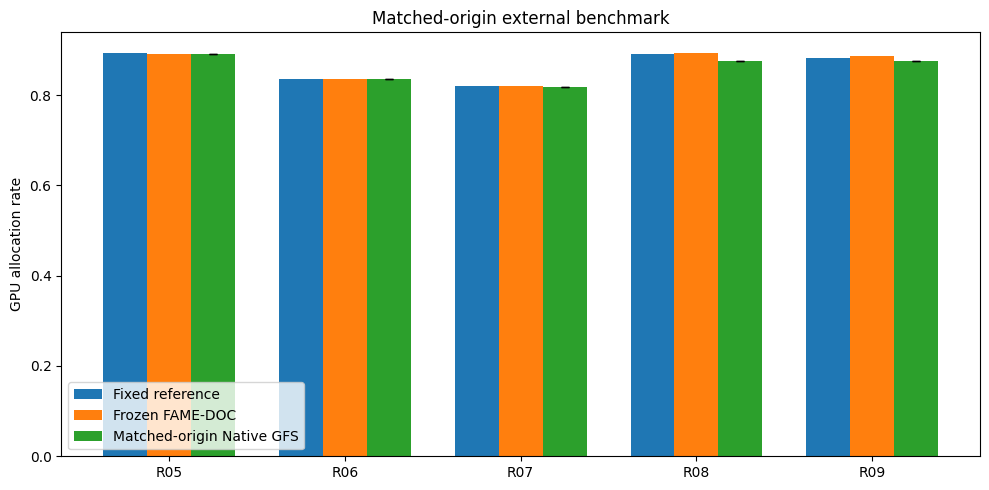

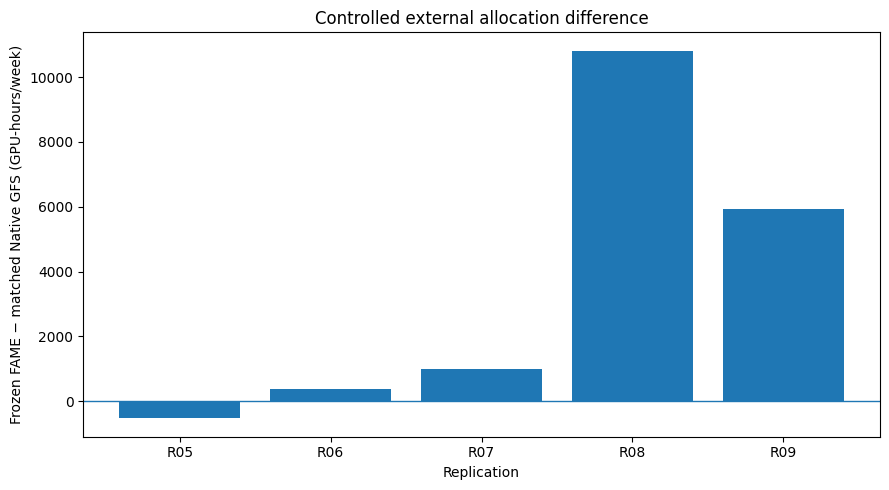

In [16]:
if not comparison.empty and comparison["matched_mean_E_allocation_rate"].notna().all():
    summary=pd.Series({
        "n_replications":len(comparison),
        "n_seeds":len(NATIVE_GFS_SEEDS),
        "mean_FAME_minus_matched_GFS_allocation":
            comparison["FAME_minus_matched_GFS_allocation"].mean(),
        "mean_FAME_minus_matched_GFS_GPU_hours":
            comparison["FAME_minus_matched_GFS_GPU_hours"].mean(),
        "median_FAME_minus_matched_GFS_GPU_hours":
            comparison["FAME_minus_matched_GFS_GPU_hours"].median(),
        "mean_FAME_minus_matched_GFS_eviction":
            comparison["FAME_minus_matched_GFS_eviction"].mean(),
        "FAME_higher_allocation_rate":
            (comparison["FAME_minus_matched_GFS_allocation"]>0).mean(),
        "FAME_lower_or_equal_eviction_rate":
            (comparison["FAME_minus_matched_GFS_eviction"]<=0).mean(),
        "FAME_higher_allocation_and_no_higher_eviction_rate":
            (
                (comparison["FAME_minus_matched_GFS_allocation"]>0)
                & (comparison["FAME_minus_matched_GFS_eviction"]<=0)
            ).mean(),
        "mean_matched_minus_continuous_GPU_hours":
            trajectory["matched_minus_continuous_GPU_hours"].mean(),
    })

    display(summary.to_frame("value"))
    summary.to_csv(OUT/"matched_origin_external_summary.csv")

    x=np.arange(len(comparison))
    w=.25

    fig,ax=plt.subplots(figsize=(10,5))
    ax.bar(x-w,comparison["reference_E_allocation"],w,label="Fixed reference")
    ax.bar(x,comparison["frozen_E_allocation"],w,label="Frozen FAME-DOC")
    ax.bar(
        x+w,
        comparison["matched_mean_E_allocation_rate"],
        w,
        yerr=comparison["matched_sd_E_allocation_rate"],
        capsize=3,
        label="Matched-origin Native GFS"
    )
    ax.set_xticks(x)
    ax.set_xticklabels(comparison["replication"])
    ax.set_ylabel("GPU allocation rate")
    ax.set_title("Matched-origin external benchmark")
    ax.legend()
    plt.tight_layout()
    fig.savefig(OUT/"matched_origin_allocation.png",dpi=180)
    plt.show()

    fig,ax=plt.subplots(figsize=(9,5))
    ax.axhline(0,linewidth=1)
    ax.bar(
        comparison["replication"],
        comparison["FAME_minus_matched_GFS_GPU_hours"]
    )
    ax.set_xlabel("Replication")
    ax.set_ylabel("Frozen FAME − matched Native GFS (GPU-hours/week)")
    ax.set_title("Controlled external allocation difference")
    plt.tight_layout()
    fig.savefig(OUT/"FAME_minus_matched_GFS_GPU_hours.png",dpi=180)
    plt.show()

In [17]:
manifest={
    "git_head":git_head,
    "replications":PRINCIPAL_REPS,
    "seeds":NATIVE_GFS_SEEDS,
    "workers":MAX_WORKERS,
    "torch_threads_per_branch":TORCH_THREADS_PER_BRANCH,
    "use_gpu":USE_GPU,
    "train_epochs":TRAIN_EPOCHS,
    "patience":PATIENCE,
    "batch_size":BATCH_SIZE,
    "dataloader_workers":DATALOADER_WORKERS,
    "guarantee_rate":.90,
    "guarantee_hour":[1],
    "FastExactDataset":True,
    "FastExact_validation":"FAST_EXACT_EQUIVALENCE_OK",
    "matched_origin":True,
}

(OUT/"matched_origin_manifest.json").write_text(
    json.dumps(manifest,indent=2),
    encoding="utf-8"
)

zip_out=ROOT/"outputs_fame_gpu_05_v7.zip"

with zipfile.ZipFile(zip_out,"w",compression=zipfile.ZIP_DEFLATED) as z:
    for p in OUT.rglob("*"):
        if p.is_file():
            z.write(p,arcname="outputs_fame_gpu_05_v7/"+p.name)

print("ZIP:",zip_out.resolve())

ZIP: C:\Users\tiago\Dropbox\Artigos\FAME\FAME\Artigo 2 - AOR\FAME_GPU\outputs_fame_gpu_05_v7.zip
